In [1]:


import time
import heapq
import matplotlib.pyplot as plt
import pandas as pd
import random

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:


parcels = [
    {"Parcel_ID": 101, "Destination": "A", "Weight": 2, "Priority": 5, "Deadline": 2},
    {"Parcel_ID": 102, "Destination": "B", "Weight": 4, "Priority": 3, "Deadline": 5},
    {"Parcel_ID": 103, "Destination": "C", "Weight": 3, "Priority": 4, "Deadline": 3},
    {"Parcel_ID": 104, "Destination": "D", "Weight": 5, "Priority": 2, "Deadline": 7},
    {"Parcel_ID": 105, "Destination": "E", "Weight": 1, "Priority": 5, "Deadline": 1}
]

# Convert data into DataFrame
df = pd.DataFrame(parcels)

# Display parcel details
print("MINI COURIER PLANNER - PARCEL DETAILS")
display(df)

MINI COURIER PLANNER - PARCEL DETAILS


,Parcel_ID,Destination,Weight,Priority,Deadline
0,101,A,2,5,2
1,102,B,4,3,5
2,103,C,3,4,3
3,104,D,5,2,7
4,105,E,1,5,1


In [3]:


sorted_parcels = sorted(
    parcels,
    key=lambda x: (-x["Priority"], x["Deadline"])
)

print("PARCELS AFTER PRIORITY SORTING")

for parcel in sorted_parcels:
    print(
        "Parcel ID:", parcel["Parcel_ID"],
        "| Priority:", parcel["Priority"],
        "| Deadline:", parcel["Deadline"]
    )

PARCELS AFTER PRIORITY SORTING
Parcel ID: 105 | Priority: 5 | Deadline: 1
Parcel ID: 101 | Priority: 5 | Deadline: 2
Parcel ID: 103 | Priority: 4 | Deadline: 3
Parcel ID: 102 | Priority: 3 | Deadline: 5
Parcel ID: 104 | Priority: 2 | Deadline: 7


In [4]:


capacity = 10

print("Maximum vehicle capacity:", capacity, "kg")

Maximum vehicle capacity: 10 kg


In [5]:
weights = [parcel["Weight"] for parcel in parcels]

values = [parcel["Priority"] for parcel in parcels]

print("Parcel weights:", weights)
print("Parcel priorities:", values)
print("Vehicle capacity:", capacity)

Parcel weights: [2, 4, 3, 5, 1]
Parcel priorities: [5, 3, 4, 2, 5]
Vehicle capacity: 10


In [6]:
n = len(weights)

# Create DP table
dp = [[0 for j in range(capacity + 1)] for i in range(n + 1)]

# Fill DP table
for i in range(1, n + 1):
    for w in range(capacity + 1):

        if weights[i - 1] <= w:

            dp[i][w] = max(
                values[i - 1] + dp[i - 1][w - weights[i - 1]],
                dp[i - 1][w]
            )

        else:
            dp[i][w] = dp[i - 1][w]

print("Dynamic Programming Table:")

display(pd.DataFrame(dp))

Dynamic Programming Table:


,0,1,2,3,4,5,6,7,8,9,10
0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,5,5,5,5,5,5,5,5,5
2,0,0,5,5,5,5,8,8,8,8,8
3,0,0,5,5,5,9,9,9,9,12,12
4,0,0,5,5,5,9,9,9,9,12,12
5,0,5,5,10,10,10,14,14,14,14,17


In [7]:


selected_parcels = []

w = capacity

for i in range(n, 0, -1):

    if dp[i][w] != dp[i - 1][w]:

        selected_parcels.append(parcels[i - 1])

        w -= weights[i - 1]

# Reverse selected parcels
selected_parcels.reverse()

print("OPTIMAL PARCEL SELECTION")

for parcel in selected_parcels:
    print(
        "Parcel ID:", parcel["Parcel_ID"],
        "| Weight:", parcel["Weight"], "kg",
        "| Priority:", parcel["Priority"]
    )

total_weight = sum(p["Weight"] for p in selected_parcels)
total_priority = sum(p["Priority"] for p in selected_parcels)

print("\nTotal Weight:", total_weight, "kg")
print("Total Priority:", total_priority)
print("Remaining Capacity:", capacity - total_weight, "kg")

OPTIMAL PARCEL SELECTION
Parcel ID: 101 | Weight: 2 kg | Priority: 5
Parcel ID: 102 | Weight: 4 kg | Priority: 3
Parcel ID: 103 | Weight: 3 kg | Priority: 4
Parcel ID: 105 | Weight: 1 kg | Priority: 5

Total Weight: 10 kg
Total Priority: 17
Remaining Capacity: 0 kg


In [8]:


graph = {
    "Warehouse": {
        "A": 4,
        "B": 2
    },

    "A": {
        "Warehouse": 4,
        "B": 1,
        "C": 5
    },

    "B": {
        "Warehouse": 2,
        "A": 1,
        "C": 8,
        "D": 10
    },

    "C": {
        "A": 5,
        "B": 8,
        "D": 2,
        "E": 6
    },

    "D": {
        "B": 10,
        "C": 2,
        "E": 3
    },

    "E": {
        "C": 6,
        "D": 3
    }
}

print("DELIVERY LOCATION GRAPH")

for location, connections in graph.items():
    print(location, "->", connections)

DELIVERY LOCATION GRAPH
Warehouse -> {'A': 4, 'B': 2}
A -> {'Warehouse': 4, 'B': 1, 'C': 5}
B -> {'Warehouse': 2, 'A': 1, 'C': 8, 'D': 10}
C -> {'A': 5, 'B': 8, 'D': 2, 'E': 6}
D -> {'B': 10, 'C': 2, 'E': 3}
E -> {'C': 6, 'D': 3}


In [9]:


def dijkstra(graph, start):

    distances = {node: float('inf') for node in graph}
    previous = {node: None for node in graph}

    distances[start] = 0

    priority_queue = [(0, start)]

    while priority_queue:

        current_distance, current_node = heapq.heappop(priority_queue)

        if current_distance > distances[current_node]:
            continue

        for neighbor, weight in graph[current_node].items():

            distance = current_distance + weight

            if distance < distances[neighbor]:

                distances[neighbor] = distance
                previous[neighbor] = current_node

                heapq.heappush(
                    priority_queue,
                    (distance, neighbor)
                )

    return distances, previous


# Run Dijkstra
distances, previous = dijkstra(graph, "Warehouse")

print("SHORTEST DISTANCES FROM WAREHOUSE")

for location, distance in distances.items():
    print(location, ":", distance, "km")

SHORTEST DISTANCES FROM WAREHOUSE
Warehouse : 0 km
A : 3 km
B : 2 km
C : 8 km
D : 10 km
E : 13 km


In [10]:


def get_path(previous, destination):

    path = []

    current = destination

    while current is not None:
        path.append(current)
        current = previous[current]

    path.reverse()

    return path


# Display shortest paths

print("SHORTEST DELIVERY PATHS")

for location in graph:

    path = get_path(previous, location)

    print(
        "Destination:", location,
        "| Path:", " -> ".join(path),
        "| Distance:", distances[location], "km"
    )

SHORTEST DELIVERY PATHS
Destination: Warehouse | Path: Warehouse | Distance: 0 km
Destination: A | Path: Warehouse -> B -> A | Distance: 3 km
Destination: B | Path: Warehouse -> B | Distance: 2 km
Destination: C | Path: Warehouse -> B -> A -> C | Distance: 8 km
Destination: D | Path: Warehouse -> B -> A -> C -> D | Distance: 10 km
Destination: E | Path: Warehouse -> B -> A -> C -> D -> E | Distance: 13 km


In [11]:


def nearest_neighbor(graph, start):

    visited = [start]
    current = start
    total_distance = 0

    while len(visited) < len(graph):

        nearest = None
        minimum_distance = float('inf')

        for neighbor, distance in graph[current].items():

            if neighbor not in visited and distance < minimum_distance:

                minimum_distance = distance
                nearest = neighbor

        if nearest is None:
            break

        visited.append(nearest)

        total_distance += minimum_distance

        current = nearest

    # Return to warehouse
    if start in graph[current]:

        total_distance += graph[current][start]
        visited.append(start)

    return visited, total_distance




route, route_distance = nearest_neighbor(graph, "Warehouse")

print("OPTIMIZED DELIVERY ROUTE:")
print(" -> ".join(route))

print("Total Route Distance:", route_distance, "km")

OPTIMIZED DELIVERY ROUTE:
Warehouse -> B -> A -> C -> D -> E
Total Route Distance: 13 km


In [12]:


def mini_courier_planner():

    print("=" * 50)
    print("       MINI COURIER PLANNER")
    print("=" * 50)

    # 1. Parcel prioritization
    print("\n1. PARCEL PRIORITIZATION")

    for parcel in sorted_parcels:
        print(
            "Parcel:", parcel["Parcel_ID"],
            "| Priority:", parcel["Priority"]
        )

    # 2. Optimal parcel selection
    print("\n2. OPTIMAL PACKAGE SELECTION")

    for parcel in selected_parcels:
        print("Selected Parcel:", parcel["Parcel_ID"])

    print("Total Weight:", total_weight, "kg")
    print("Total Priority:", total_priority)

    # 3. Shortest paths
    print("\n3. SHORTEST DELIVERY DISTANCES")

    for location, distance in distances.items():
        print(location, ":", distance, "km")

    # 4. Delivery route
    print("\n4. FINAL DELIVERY ROUTE")

    print(" -> ".join(route))

    print("Total Route Distance:", route_distance, "km")

    print("\nCOURIER PLANNING COMPLETED!")


# Execute complete planner
mini_courier_planner()

       MINI COURIER PLANNER

1. PARCEL PRIORITIZATION
Parcel: 105 | Priority: 5
Parcel: 101 | Priority: 5
Parcel: 103 | Priority: 4
Parcel: 102 | Priority: 3
Parcel: 104 | Priority: 2

2. OPTIMAL PACKAGE SELECTION
Selected Parcel: 101
Selected Parcel: 102
Selected Parcel: 103
Selected Parcel: 105
Total Weight: 10 kg
Total Priority: 17

3. SHORTEST DELIVERY DISTANCES
Warehouse : 0 km
A : 3 km
B : 2 km
C : 8 km
D : 10 km
E : 13 km

4. FINAL DELIVERY ROUTE
Warehouse -> B -> A -> C -> D -> E
Total Route Distance: 13 km

COURIER PLANNING COMPLETED!


In [13]:


# 1. Sorting execution time
start = time.perf_counter()

sorted(parcels, key=lambda x: (-x["Priority"], x["Deadline"]))

sorting_time = time.perf_counter() - start


# 2. Knapsack execution time
start = time.perf_counter()

n = len(weights)

dp_test = [[0 for j in range(capacity + 1)] for i in range(n + 1)]

for i in range(1, n + 1):
    for w in range(capacity + 1):

        if weights[i - 1] <= w:
            dp_test[i][w] = max(
                values[i - 1] + dp_test[i - 1][w - weights[i - 1]],
                dp_test[i - 1][w]
            )
        else:
            dp_test[i][w] = dp_test[i - 1][w]

knapsack_time = time.perf_counter() - start


# 3. Dijkstra execution time
start = time.perf_counter()

dijkstra(graph, "Warehouse")

dijkstra_time = time.perf_counter() - start


# 4. Nearest Neighbor execution time
start = time.perf_counter()

nearest_neighbor(graph, "Warehouse")

tsp_time = time.perf_counter() - start


# Display results
print("ALGORITHM PERFORMANCE ANALYSIS")
print("--------------------------------")

print("Sorting Time:", sorting_time, "seconds")
print("Knapsack Time:", knapsack_time, "seconds")
print("Dijkstra Time:", dijkstra_time, "seconds")
print("Nearest Neighbor Time:", tsp_time, "seconds")

ALGORITHM PERFORMANCE ANALYSIS
--------------------------------
Sorting Time: 7.558400011475896e-05 seconds
Knapsack Time: 0.00020212500021443702 seconds
Dijkstra Time: 7.637499993506935e-05 seconds
Nearest Neighbor Time: 0.0003764170000977174 seconds


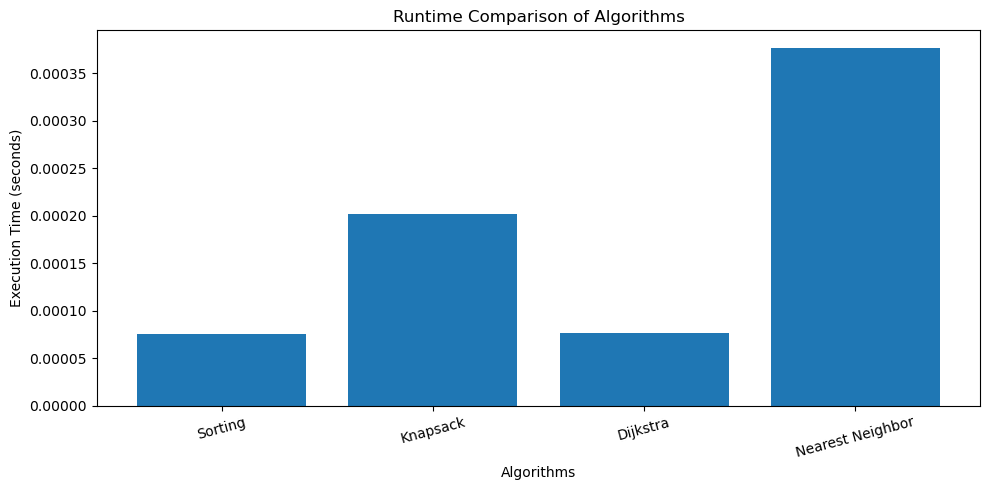

In [14]:


algorithms = [
    "Sorting",
    "Knapsack",
    "Dijkstra",
    "Nearest Neighbor"
]

execution_times = [
    sorting_time,
    knapsack_time,
    dijkstra_time,
    tsp_time
]

plt.figure(figsize=(10, 5))

plt.bar(algorithms, execution_times)

plt.title("Runtime Comparison of Algorithms")
plt.xlabel("Algorithms")
plt.ylabel("Execution Time (seconds)")

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [15]:


large_parcels = []

for i in range(500):

    parcel = {
        "Parcel_ID": 1000 + i,
        "Destination": random.choice(["A", "B", "C", "D", "E"]),
        "Weight": random.randint(1, 10),
        "Priority": random.randint(1, 5),
        "Deadline": random.randint(1, 10)
    }

    large_parcels.append(parcel)


print("Large Dataset Created Successfully!")
print("Total Parcels:", len(large_parcels))

# Display first 10 parcels
display(pd.DataFrame(large_parcels).head(10))

Large Dataset Created Successfully!
Total Parcels: 500


,Parcel_ID,Destination,Weight,Priority,Deadline
0,1000,D,8,3,4
1,1001,C,6,4,6
2,1002,A,1,1,1
3,1003,E,5,4,10
4,1004,B,1,4,8
5,1005,C,10,1,7
6,1006,B,4,3,10
7,1007,B,8,3,1
8,1008,C,9,3,4
9,1009,A,4,1,6


In [16]:


dataset_sizes = [5, 100, 500, 1000]

sorting_results = []

for size in dataset_sizes:

    test_data = [
        {
            "Parcel_ID": i,
            "Priority": random.randint(1, 5),
            "Deadline": random.randint(1, 10)
        }
        for i in range(size)
    ]

    start = time.perf_counter()

    sorted_data = sorted(
        test_data,
        key=lambda x: (-x["Priority"], x["Deadline"])
    )

    end = time.perf_counter()

    sorting_results.append(end - start)

    print(
        "Parcels:", size,
        "| Execution Time:", end - start, "seconds"
    )

Parcels: 5 | Execution Time: 7.666999863431556e-06 seconds
Parcels: 100 | Execution Time: 3.766700001506251e-05 seconds
Parcels: 500 | Execution Time: 0.00017808399979912792 seconds
Parcels: 1000 | Execution Time: 0.00043662500002028537 seconds


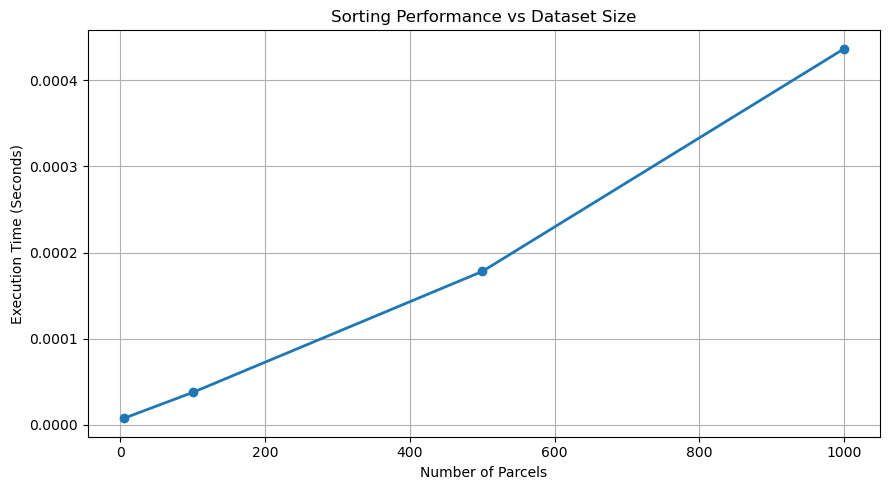

In [17]:


plt.figure(figsize=(9, 5))

plt.plot(
    dataset_sizes,
    sorting_results,
    marker='o',
    linewidth=2
)

plt.title("Sorting Performance vs Dataset Size")
plt.xlabel("Number of Parcels")
plt.ylabel("Execution Time (Seconds)")

plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:


dataset_sizes = [5, 100, 500, 1000]

knapsack_results = []

for size in dataset_sizes:

    test_weights = [
        random.randint(1, 10) for _ in range(size)
    ]

    test_values = [
        random.randint(1, 5) for _ in range(size)
    ]

    test_capacity = 100

    start = time.perf_counter()

    dp_temp = [
        [0 for j in range(test_capacity + 1)]
        for i in range(size + 1)
    ]

    for i in range(1, size + 1):
        for w in range(test_capacity + 1):

            if test_weights[i - 1] <= w:

                dp_temp[i][w] = max(
                    test_values[i - 1] +
                    dp_temp[i - 1][w - test_weights[i - 1]],

                    dp_temp[i - 1][w]
                )

            else:
                dp_temp[i][w] = dp_temp[i - 1][w]

    end = time.perf_counter()

    execution_time = end - start

    knapsack_results.append(execution_time)

    print(
        "Parcels:", size,
        "| Execution Time:", execution_time, "seconds"
    )

Parcels: 5 | Execution Time: 0.00024395799982812605 seconds
Parcels: 100 | Execution Time: 0.004616499999883672 seconds
Parcels: 500 | Execution Time: 0.021963249999771506 seconds
Parcels: 1000 | Execution Time: 0.031649541999740904 seconds


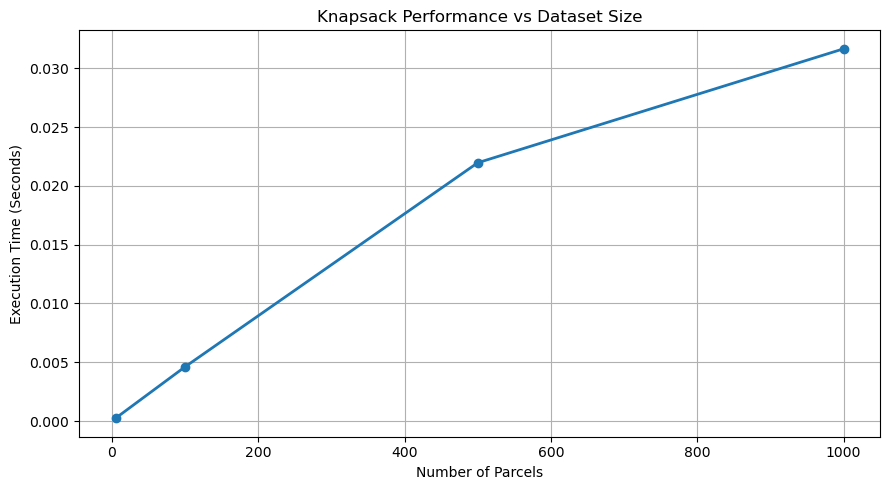

In [19]:


plt.figure(figsize=(9, 5))

plt.plot(
    dataset_sizes,
    knapsack_results,
    marker='o',
    linewidth=2
)

plt.title("Knapsack Performance vs Dataset Size")
plt.xlabel("Number of Parcels")
plt.ylabel("Execution Time (Seconds)")

plt.grid(True)
plt.tight_layout()
plt.show()

In [20]:


graph_sizes = [5, 100, 500, 1000]

dijkstra_results = []

for size in graph_sizes:

    test_graph = {}

    # Create graph locations
    for i in range(size):
        test_graph[i] = {}

    # Connect each location to the next location
    for i in range(size - 1):

        weight = random.randint(1, 10)

        test_graph[i][i + 1] = weight
        test_graph[i + 1][i] = weight

    # Add additional connections
    for i in range(size):
        for _ in range(3):

            neighbor = random.randint(0, size - 1)

            if neighbor != i:

                weight = random.randint(1, 10)

                test_graph[i][neighbor] = weight
                test_graph[neighbor][i] = weight

    # Measure execution time
    start = time.perf_counter()

    dijkstra(test_graph, 0)

    end = time.perf_counter()

    execution_time = end - start

    dijkstra_results.append(execution_time)

    print(
        "Locations:", size,
        "| Execution Time:", execution_time, "seconds"
    )

Locations: 5 | Execution Time: 1.995899992834893e-05 seconds
Locations: 100 | Execution Time: 0.00016566700014664093 seconds
Locations: 500 | Execution Time: 0.000739208000140934 seconds
Locations: 1000 | Execution Time: 0.0016551250000702566 seconds


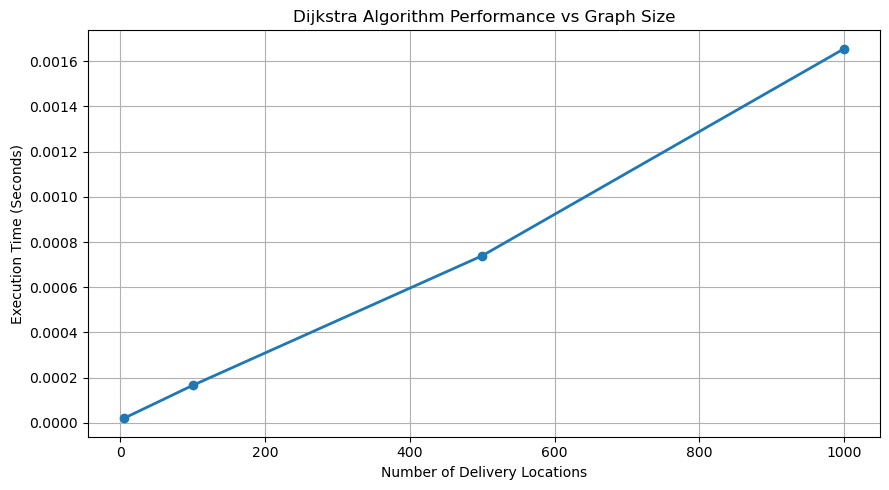

In [21]:



plt.figure(figsize=(9, 5))

plt.plot(
    graph_sizes,
    dijkstra_results,
    marker='o',
    linewidth=2
)

plt.title("Dijkstra Algorithm Performance vs Graph Size")
plt.xlabel("Number of Delivery Locations")
plt.ylabel("Execution Time (Seconds)")

plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:


tsp_results = []

for size in graph_sizes:

    test_graph = {}

    # Create locations
    for i in range(size):
        test_graph[i] = {}

    # Connect every location to every other location
    for i in range(size):
        for j in range(size):

            if i != j:
                test_graph[i][j] = random.randint(1, 20)

    # Measure execution time
    start = time.perf_counter()

    nearest_neighbor(test_graph, 0)

    end = time.perf_counter()

    execution_time = end - start

    tsp_results.append(execution_time)

    print(
        "Locations:", size,
        "| Execution Time:", execution_time, "seconds"
    )

Locations: 5 | Execution Time: 1.2166000033175806e-05 seconds
Locations: 100 | Execution Time: 0.003484541000034369 seconds
Locations: 500 | Execution Time: 0.24726583300025595 seconds
Locations: 1000 | Execution Time: 1.9927791249997426 seconds


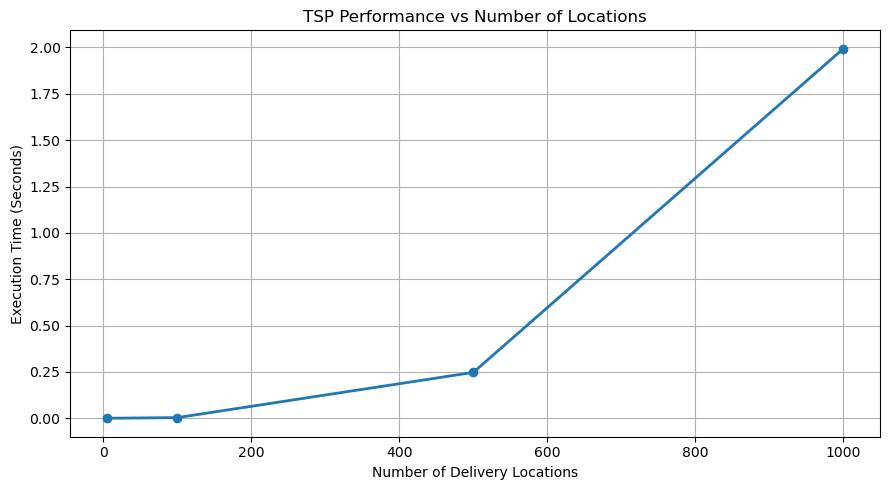

In [23]:


plt.figure(figsize=(9, 5))

plt.plot(
    graph_sizes,
    tsp_results,
    marker='o',
    linewidth=2
)

plt.title("TSP Performance vs Number of Locations")
plt.xlabel("Number of Delivery Locations")
plt.ylabel("Execution Time (Seconds)")

plt.grid(True)
plt.tight_layout()
plt.show()

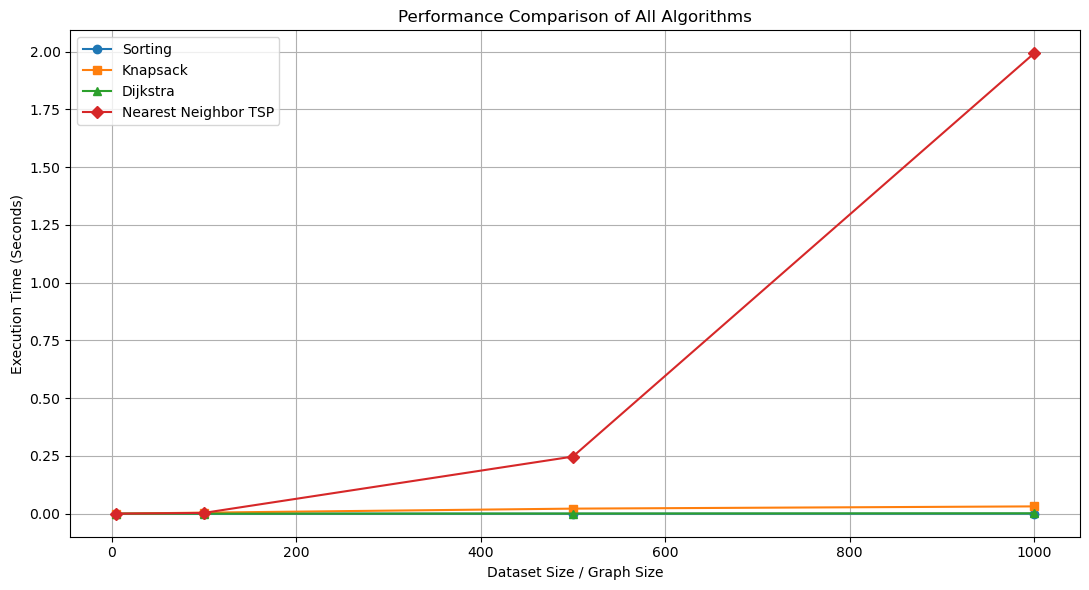

In [24]:


plt.figure(figsize=(11, 6))

plt.plot(dataset_sizes, sorting_results,
         marker='o', label='Sorting')

plt.plot(dataset_sizes, knapsack_results,
         marker='s', label='Knapsack')

plt.plot(graph_sizes, dijkstra_results,
         marker='^', label='Dijkstra')

plt.plot(graph_sizes, tsp_results,
         marker='D', label='Nearest Neighbor TSP')

plt.title("Performance Comparison of All Algorithms")

plt.xlabel("Dataset Size / Graph Size")
plt.ylabel("Execution Time (Seconds)")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [25]:


import os
import json

# Create datasets folder
os.makedirs("datasets", exist_ok=True)

# Save original parcel dataset
pd.DataFrame(parcels).to_csv(
    "datasets/parcels.csv",
    index=False
)

# Save large parcel dataset
pd.DataFrame(large_parcels).to_csv(
    "datasets/large_parcels.csv",
    index=False
)

# Save delivery graph
with open("datasets/delivery_graph.json", "w") as file:
    json.dump(graph, file, indent=4)

print("DATASETS SAVED SUCCESSFULLY!")

print("1. parcels.csv")
print("2. large_parcels.csv")
print("3. delivery_graph.json")

DATASETS SAVED SUCCESSFULLY!
1. parcels.csv
2. large_parcels.csv
3. delivery_graph.json


In [26]:
# Step 27: Save performance graphs

import os
import matplotlib.pyplot as plt

os.makedirs("images", exist_ok=True)

# 1. Sorting graph
plt.figure(figsize=(9, 5))
plt.plot(dataset_sizes, sorting_results, marker='o')
plt.title("Sorting Performance")
plt.xlabel("Number of Parcels")
plt.ylabel("Execution Time (Seconds)")
plt.grid(True)
plt.savefig("images/sorting_performance.png")
plt.close()


# 2. Knapsack graph
plt.figure(figsize=(9, 5))
plt.plot(dataset_sizes, knapsack_results, marker='o')
plt.title("Knapsack Performance")
plt.xlabel("Number of Parcels")
plt.ylabel("Execution Time (Seconds)")
plt.grid(True)
plt.savefig("images/knapsack_performance.png")
plt.close()


# 3. Dijkstra graph
plt.figure(figsize=(9, 5))
plt.plot(graph_sizes, dijkstra_results, marker='o')
plt.title("Dijkstra Performance")
plt.xlabel("Number of Locations")
plt.ylabel("Execution Time (Seconds)")
plt.grid(True)
plt.savefig("images/dijkstra_performance.png")
plt.close()


# 4. TSP graph
plt.figure(figsize=(9, 5))
plt.plot(graph_sizes, tsp_results, marker='o')
plt.title("TSP Performance")
plt.xlabel("Number of Locations")
plt.ylabel("Execution Time (Seconds)")
plt.grid(True)
plt.savefig("images/tsp_performance.png")
plt.close()


print("All four performance graphs saved successfully!")

All four performance graphs saved successfully!


In [27]:
#create requirements.txt

requirements = """
pandas
matplotlib
"""

with open("requirements.txt", "w") as file:
    file.write(requirements.strip())

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [29]:
# Create .gitignore

gitignore_content = """
.ipynb_checkpoints/
__pycache__/
*.pyc
.DS_Store
"""

with open(".gitignore", "w") as file:
    file.write(gitignore_content.strip())

print(".gitignore created successfully!")

.gitignore created successfully!


In [30]:
# Step 30: Create README.md

readme_content = """
# Mini-Courier Planner

## Project Overview
Mini-Courier Planner is a Python-based project that helps plan parcel deliveries by prioritizing parcels, optimizing box capacity, and finding efficient delivery routes.

## Features
- Parcel prioritization using sorting.
- Optimal parcel selection using Dynamic Programming (0/1 Knapsack).
- Shortest path calculation using Dijkstra's Algorithm.
- Delivery route optimization using Nearest Neighbor TSP approximation.
- Performance analysis using runtime measurements and graphs.

## Algorithms Used
1. Sorting Algorithm
2. Dynamic Programming (0/1 Knapsack)
3. Dijkstra's Shortest Path Algorithm
4. Nearest Neighbor TSP Approximation

## Technologies Used
- Python
- Pandas
- Matplotlib
- Jupyter Notebook

## Project Structure
- mini_courier_planner.ipynb: Main project code.
- requirements.txt: Required Python libraries.
- datasets/: Parcel and delivery graph datasets.
- images/: Performance graphs.
- README.md: Project documentation.

## How to Run
1. Install Python.
2. Install the required libraries using:

   pip install -r requirements.txt

3. Open Jupyter Notebook.
4. Open mini_courier_planner.ipynb.
5. Run all cells from beginning to end.

## Performance Analysis
The project measures the execution time of sorting, Knapsack, Dijkstra, and TSP algorithms on different dataset sizes.

## Conclusion
This project demonstrates how sorting, dynamic programming, graph algorithms, and approximation techniques can be combined to solve a practical courier delivery planning problem.
"""

with open("README.md", "w") as file:
    file.write(readme_content.strip())

print("README.md created successfully!")

README.md created successfully!


In [31]:
#  Check Project Structure

import os

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints", "__pycache__"]]

    level = root.count(os.sep)
    indent = "    " * level

    print(indent + os.path.basename(root) + "/")

    for file in files:
        print(indent + "    " + file)

./
    mini_courier_planner.ipynb
    requirements.txt
    README.md
    .gitignore
    images/
        knapsack_performance.png
        tsp_performance.png
        sorting_performance.png
        dijkstra_performance.png
    datasets/
        parcels.csv
        delivery_graph.json
        large_parcels.csv


In [32]:
#  Check Delivery Route

print("Current Delivery Route:", route)
print("Total Route Distance:", route_distance, "km")
print("Selected Parcels:", [p["Parcel_ID"] for p in selected_parcels])
print("Selected Destinations:", [p["Destination"] for p in selected_parcels])

Current Delivery Route: ['Warehouse', 'B', 'A', 'C', 'D', 'E']
Total Route Distance: 13 km
Selected Parcels: [101, 102, 103, 105]
Selected Destinations: ['A', 'B', 'C', 'E']


In [33]:
# Optimize Route for Selected Parcels

# Get unique destinations of selected parcels
selected_destinations = list(dict.fromkeys(
    p["Destination"] for p in selected_parcels
))

# Include Warehouse as starting and ending point
locations = ["Warehouse"] + selected_destinations

# Calculate shortest distances between all locations using Dijkstra
distance_graph = {}

for location in locations:
    distances, previous = dijkstra(graph, location)

    distance_graph[location] = {}

    for destination in locations:
        if destination != location:
            distance_graph[location][destination] = distances[destination]

# Generate optimized route using Nearest Neighbor
optimized_route, optimized_distance = nearest_neighbor(
    distance_graph, "Warehouse"
)

# Display results
print("Selected Destinations:", selected_destinations)

print("Optimized Delivery Route:", " -> ".join(optimized_route))

print("Total Optimized Distance:", optimized_distance, "km")

Selected Destinations: ['A', 'B', 'C', 'E']
Optimized Delivery Route: Warehouse -> B -> A -> C -> E -> Warehouse
Total Optimized Distance: 26 km


In [34]:
#  Verify Optimized Route

print("Route:", optimized_route)

print("Total Distance:", optimized_distance, "km")

print("Number of Delivery Locations:",
      len(optimized_route) - 2)

print("Starts at Warehouse:",
      optimized_route[0] == "Warehouse")

print("Returns to Warehouse:",
      optimized_route[-1] == "Warehouse")

print("All Selected Destinations Visited:",
      set(selected_destinations).issubset(set(optimized_route)))

Route: ['Warehouse', 'B', 'A', 'C', 'E', 'Warehouse']
Total Distance: 26 km
Number of Delivery Locations: 4
Starts at Warehouse: True
Returns to Warehouse: True
All Selected Destinations Visited: True


In [35]:
#  Final Integrated Courier Planner

def mini_courier_planner():

    print("========== MINI COURIER PLANNER ==========")

    # 1. Sort parcels by priority and deadline
    sorted_parcels = sorted(
        parcels,
        key=lambda x: (-x["Priority"], x["Deadline"])
    )

    print("\n1. PRIORITIZED PARCELS")
    display(pd.DataFrame(sorted_parcels))

    # 2. Select parcels using Knapsack
    print("\n2. SELECTED PARCELS")

    for parcel in selected_parcels:
        print(parcel)

    print("Total Weight:", total_weight, "kg")
    print("Total Priority:", total_priority)

    # 3. Find shortest paths using Dijkstra
    print("\n3. SHORTEST DISTANCES FROM WAREHOUSE")

    distances, previous = dijkstra(graph, "Warehouse")

    for location, distance in distances.items():
        print(location, ":", distance, "km")

    # 4. Generate optimized delivery route
    print("\n4. OPTIMIZED DELIVERY ROUTE")

    print(" -> ".join(optimized_route))
    print("Total Route Distance:", optimized_distance, "km")

    print("\n========== PLANNING COMPLETED ==========")


# Run complete project
mini_courier_planner()

========== MINI COURIER PLANNER ==========

1. PRIORITIZED PARCELS


,Parcel_ID,Destination,Weight,Priority,Deadline
0,105,E,1,5,1
1,101,A,2,5,2
2,103,C,3,4,3
3,102,B,4,3,5
4,104,D,5,2,7



2. SELECTED PARCELS
{'Parcel_ID': 101, 'Destination': 'A', 'Weight': 2, 'Priority': 5, 'Deadline': 2}
{'Parcel_ID': 102, 'Destination': 'B', 'Weight': 4, 'Priority': 3, 'Deadline': 5}
{'Parcel_ID': 103, 'Destination': 'C', 'Weight': 3, 'Priority': 4, 'Deadline': 3}
{'Parcel_ID': 105, 'Destination': 'E', 'Weight': 1, 'Priority': 5, 'Deadline': 1}
Total Weight: 10 kg
Total Priority: 17

3. SHORTEST DISTANCES FROM WAREHOUSE
Warehouse : 0 km
A : 3 km
B : 2 km
C : 8 km
D : 10 km
E : 13 km

4. OPTIMIZED DELIVERY ROUTE
Warehouse -> B -> A -> C -> E -> Warehouse
Total Route Distance: 26 km

========== PLANNING COMPLETED ==========


In [36]:
#  Final Project Validation

print("========== PROJECT VALIDATION ==========")

# Check parcel capacity
assert total_weight <= capacity
print("1. Parcel capacity check: PASSED")

# Check selected parcels
assert len(selected_parcels) > 0
print("2. Parcel selection check: PASSED")

# Check route starts and ends at Warehouse
assert optimized_route[0] == "Warehouse"
assert optimized_route[-1] == "Warehouse"
print("3. Warehouse route check: PASSED")

# Check all selected destinations are visited
assert set(selected_destinations).issubset(set(optimized_route))
print("4. Destination coverage check: PASSED")

# Check route distance
assert optimized_distance > 0
print("5. Route distance check: PASSED")

print("\nALL PROJECT VALIDATION TESTS PASSED!")

========== PROJECT VALIDATION ==========
1. Parcel capacity check: PASSED
2. Parcel selection check: PASSED
3. Warehouse route check: PASSED
4. Destination coverage check: PASSED
5. Route distance check: PASSED

ALL PROJECT VALIDATION TESTS PASSED!


In [37]:
#  Verify Performance Graphs

import os

graph_files = [
    "images/sorting_performance.png",
    "images/knapsack_performance.png",
    "images/dijkstra_performance.png",
    "images/tsp_performance.png"
]

print("========== PERFORMANCE GRAPH CHECK ==========")

for file in graph_files:
    if os.path.exists(file):
        print(file, " - SAVED SUCCESSFULLY")
    else:
        print(file, " - NOT FOUND")

print("\nGRAPH VERIFICATION COMPLETED!")

========== PERFORMANCE GRAPH CHECK ==========
images/sorting_performance.png  - SAVED SUCCESSFULLY
images/knapsack_performance.png  - SAVED SUCCESSFULLY
images/dijkstra_performance.png  - SAVED SUCCESSFULLY
images/tsp_performance.png  - SAVED SUCCESSFULLY

GRAPH VERIFICATION COMPLETED!


In [38]:
#  Compare Algorithm Performance

print("========== ALGORITHM PERFORMANCE ==========")

print("\n1. SORTING PERFORMANCE")
display(pd.DataFrame(sorting_results))

print("\n2. KNAPSACK PERFORMANCE")
display(pd.DataFrame(knapsack_results))

print("\n3. DIJKSTRA PERFORMANCE")
display(pd.DataFrame(dijkstra_results))

print("\n4. TSP PERFORMANCE")
display(pd.DataFrame(tsp_results))

========== ALGORITHM PERFORMANCE ==========

1. SORTING PERFORMANCE


,0
0,0.000008
1,0.000038
2,0.000178
3,0.000437



2. KNAPSACK PERFORMANCE


,0
0,0.000244
1,0.004616
2,0.021963
3,0.031650



3. DIJKSTRA PERFORMANCE


,0
0,0.000020
1,0.000166
2,0.000739
3,0.001655



4. TSP PERFORMANCE


,0
0,0.000012
1,0.003485
2,0.247266
3,1.992779


In [39]:
#  Time and Space Complexity Analysis

complexity_data = {
    "Algorithm": [
        "Sorting",
        "Knapsack (Dynamic Programming)",
        "Dijkstra",
        "Nearest Neighbor TSP"
    ],
    "Time Complexity": [
        "O(n log n)",
        "O(n x C)",
        "O((V + E) log V)",
        "O(V^2)"
    ],
    "Space Complexity": [
        "O(n)",
        "O(n x C)",
        "O(V + E)",
        "O(V)"
    ]
}

complexity_df = pd.DataFrame(complexity_data)

print("========== ALGORITHM COMPLEXITY ANALYSIS ==========")

display(complexity_df)

========== ALGORITHM COMPLEXITY ANALYSIS ==========


,Algorithm,Time Complexity,Space Complexity
0,Sorting,O(n log n),O(n)
1,Knapsack (Dynamic Programming),O(n x C),O(n x C)
2,Dijkstra,O((V + E) log V),O(V + E)
3,Nearest Neighbor TSP,O(V^2),O(V)


In [40]:
#  Display TSP Performance

print("========== TSP PERFORMANCE ==========")

display(pd.DataFrame(tsp_results))

========== TSP PERFORMANCE ==========


,0
0,0.000012
1,0.003485
2,0.247266
3,1.992779


In [42]:
#  Generate Performance Report

report = """
MINI-COURIER PLANNER
PERFORMANCE ANALYSIS REPORT

1. SORTING
Sorting was used to prioritize parcels based on priority and deadline.
It showed fast execution across different dataset sizes.

2. KNAPSACK
Dynamic Programming was used to select parcels within the
available box capacity.
Its runtime increased with the number of parcels.

3. DIJKSTRA
Dijkstra's algorithm was used to calculate shortest paths
between the warehouse and delivery locations.
It performed efficiently on the tested graphs.

4. NEAREST NEIGHBOR TSP
Nearest Neighbor approximation was used to generate
an optimized delivery route.
Its execution time increased significantly for larger graphs.

5. CONCLUSION
The project successfully combines sorting, dynamic programming,
shortest-path algorithms, and route approximation techniques
to solve a courier delivery planning problem.
"""

with open("performance_report.txt", "w") as file:
    file.write(report.strip())

print("Performance report created successfully!")

Performance report created successfully!


In [43]:
#  Update README with Complexity Analysis

with open("README.md", "a") as file:
    file.write("""

## Algorithm Complexity Analysis

| Algorithm | Time Complexity | Space Complexity |
|---|---|---|
| Sorting | O(n log n) | O(n) |
| Knapsack (Dynamic Programming) | O(n x C) | O(n x C) |
| Dijkstra | O((V + E) log V) | O(V + E) |
| Nearest Neighbor TSP | O(V^2) | O(V) |

Where:
- n = Number of parcels
- C = Knapsack capacity
- V = Number of graph vertices
- E = Number of graph edges

## Performance Analysis

The project evaluates four algorithms using different input sizes.

- Sorting: Fast execution for larger parcel datasets.
- Knapsack: Execution time increases with the number of parcels.
- Dijkstra: Efficient shortest-path calculation on tested graphs.
- Nearest Neighbor TSP: Execution time increases significantly for larger graphs.

Performance graphs are available in the images/ folder.

Detailed performance results are available in performance_report.txt.
""")

print("README.md updated successfully!")

README.md updated successfully!


In [44]:
#  Create Screenshots Folder

import os

os.makedirs("screenshots", exist_ok=True)

print("Screenshots folder created successfully!")

Screenshots folder created successfully!


In [45]:
#  Copy Performance Graphs

import shutil
import os

graph_files = [
    "sorting_performance.png",
    "knapsack_performance.png",
    "dijkstra_performance.png",
    "tsp_performance.png"
]

for graph in graph_files:
    source = os.path.join("images", graph)
    destination = os.path.join("screenshots", graph)

    shutil.copy(source, destination)

print("All four performance graphs copied successfully!")

All four performance graphs copied successfully!


In [46]:
#  Final Project File Verification

import os

required_files = [
    "mini_courier_planner.ipynb",
    "README.md",
    "requirements.txt",
    ".gitignore",
    "performance_report.txt",
    "datasets/parcels.csv",
    "datasets/large_parcels.csv",
    "datasets/delivery_graph.json",
    "images/sorting_performance.png",
    "images/knapsack_performance.png",
    "images/dijkstra_performance.png",
    "images/tsp_performance.png"
]

print("========== FINAL PROJECT FILE CHECK ==========")

for file in required_files:
    if os.path.exists(file):
        print("✓", file, "- FOUND")
    else:
        print("✗", file, "- MISSING")

print("\nFILE VERIFICATION COMPLETED!")

========== FINAL PROJECT FILE CHECK ==========
✓ mini_courier_planner.ipynb - FOUND
✓ README.md - FOUND
✓ requirements.txt - FOUND
✓ .gitignore - FOUND
✓ performance_report.txt - FOUND
✓ datasets/parcels.csv - FOUND
✓ datasets/large_parcels.csv - FOUND
✓ datasets/delivery_graph.json - FOUND
✓ images/sorting_performance.png - FOUND
✓ images/knapsack_performance.png - FOUND
✓ images/dijkstra_performance.png - FOUND
✓ images/tsp_performance.png - FOUND

FILE VERIFICATION COMPLETED!


In [47]:
# Create Project ZIP Backup

import zipfile
import os

project_items = [
    "mini_courier_planner.ipynb",
    "README.md",
    "requirements.txt",
    ".gitignore",
    "performance_report.txt",
    "datasets",
    "images",
    "screenshots"
]

with zipfile.ZipFile(
    "Mini-Courier-Planner-Backup.zip", "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for item in project_items:
        if os.path.isfile(item):
            zip_file.write(item)

        elif os.path.isdir(item):
            for root, dirs, files in os.walk(item):
                dirs[:] = [
                    d for d in dirs
                    if d not in [".ipynb_checkpoints", "__pycache__"]
                ]

                for file in files:
                    file_path = os.path.join(root, file)
                    zip_file.write(file_path)

print("Project ZIP backup created successfully!")

Project ZIP backup created successfully!
